# Task 3 — Spending Prediction (Regression)
**Team ML003 · CPE342 Player Intelligence System**

**Goal:** predict `spending_30d` for each player. **Metric:** NMAE score = 1 / (1 + Σ|y − ŷ| / Σy), higher is better.
**Final model:** hurdle model = LightGBM P(y > 0) + CatBoost multi-quantile on log(y / prev_month_spending), predict the mixture median. 10 + 10 seeds.
**Result:** OOF **0.7954** (honest baseline 0.7919). Confirmed on the public LB: replacing T3 by all-zeros cost exactly 0.2 × 0.295.

Contents: 1 Data & metric · 2 EDA findings · 3 Methodology · 4 Key experiment (offset target) · 5 Final model · 6 What did not work · 7 Ceiling · 8 Submission

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata, ks_2samp
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
# notebook runs from the repo root (Kaggle-ML/)
if os.path.basename(os.getcwd()) == "report_notebooks": os.chdir("..")
print("cwd:", os.getcwd())

sys.path.insert(0, "t3/research")
import common
from common import nmae, hurdle_median, prev_offset, extra_feats
D = common.load(); y, F = D["y"], D["folds"]; n = len(y)
raw = pd.read_csv("cpe342-kaggle-main/03_regression/train.csv"); raw_te = pd.read_csv("cpe342-kaggle-main/03_regression/test.csv")
print("train", raw.shape, "| test", raw_te.shape)

cwd: C:\Users\kiati\Documents\Kaggle-ML


train (104000, 34) | test (25889, 33)


## 1. Data & metric
- 104,000 train rows, 32 features (activity, social, purchase history, `segment`), target `spending_30d`.
- The metric is a normalised **MAE**. For MAE the optimal point prediction is the **median** of the predictive distribution, not the mean. This drives the whole design.
- Validation: 5-fold StratifiedKFold (seed 42) on strata {zero, payer quartile 1–4}. Every number below is out-of-fold (OOF).

zeros: 48.1%   mean 10497   median 79   p99 150032   max 300000


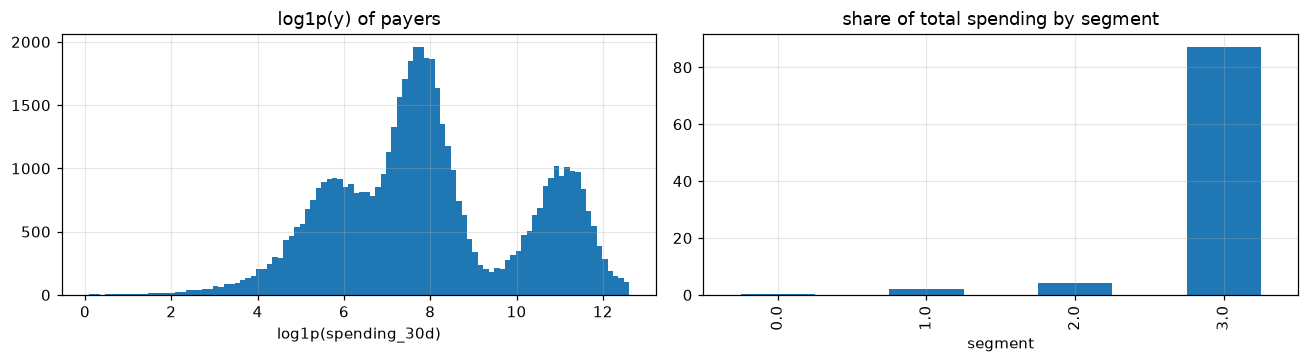

,rows %,zero %,mean y,share of Σy %
segment,,,,
0.0,40.0,72.4,74.0,0.3
1.0,25.0,48.0,944.4,2.1
2.0,20.2,30.6,2283.8,4.1
3.0,14.9,7.1,65357.7,87.3


In [2]:
print("zeros: %.1f%%   mean %.0f   median %.0f   p99 %.0f   max %.0f" % (100 * (y == 0).mean(), y.mean(), np.median(y), np.quantile(y, .99), y.max()))
seg = raw.segment
t = pd.DataFrame({"rows %": seg.value_counts(normalize=True).sort_index() * 100,
                  "zero %": raw.groupby("segment").spending_30d.apply(lambda v: (v == 0).mean() * 100),
                  "mean y": raw.groupby("segment").spending_30d.mean(),
                  "share of Σy %": raw.groupby("segment").spending_30d.sum() / raw.spending_30d.sum() * 100})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(np.log1p(y[y > 0]), 100); ax[0].set_title("log1p(y) of payers"); ax[0].set_xlabel("log1p(spending_30d)")
t["share of Σy %"].plot.bar(ax=ax[1], title="share of total spending by segment"); plt.tight_layout(); plt.show()
t.round(1)

**Findings:** ~48% zeros, a heavy right tail, and segment 3 ("whales") holds most of Σy, so it also holds most of the absolute error.

## 2. EDA findings
### 2.1 Exact identities between columns
The purchase columns are linked by exact formulas. We use them to fill missing values with no error.

In [3]:
d = raw.dropna(subset=["historical_spending", "total_transactions", "avg_transaction_value", "purchases_on_discount", "discount_rate_used"])
e1 = (d.historical_spending - d.total_transactions * d.avg_transaction_value).abs() / d.historical_spending.clip(lower=1)
e2 = (d.purchases_on_discount - d.total_transactions * d.discount_rate_used).abs()
print("historical_spending = total_transactions × avg_transaction_value : median rel. error %.2e" % e1.median())
print("purchases_on_discount = total_transactions × discount_rate_used : median abs. error %.2e" % e2.median())
cols = ["historical_spending", "total_transactions", "avg_transaction_value", "purchases_on_discount", "discount_rate_used"]
filled = common.exact_fill(raw)
pd.DataFrame({"NaN before": raw[cols].isna().mean() * 100, "NaN after exact fill": filled[cols].isna().mean() * 100}).round(2)

historical_spending = total_transactions × avg_transaction_value : median rel. error 0.00e+00
purchases_on_discount = total_transactions × discount_rate_used : median abs. error 0.00e+00


,NaN before,NaN after exact fill
historical_spending,5.80,0.38
total_transactions,5.83,0.10
avg_transaction_value,5.76,0.44
purchases_on_discount,5.85,0.35
discount_rate_used,5.87,0.41


### 2.2 Spending is proportional to last month's spending
Inside each segment, log(y) is almost a straight line in log(prev_month_spending) with slope ≈ 1.
So y ≈ prev_month × (segment-dependent multiplier) × noise.

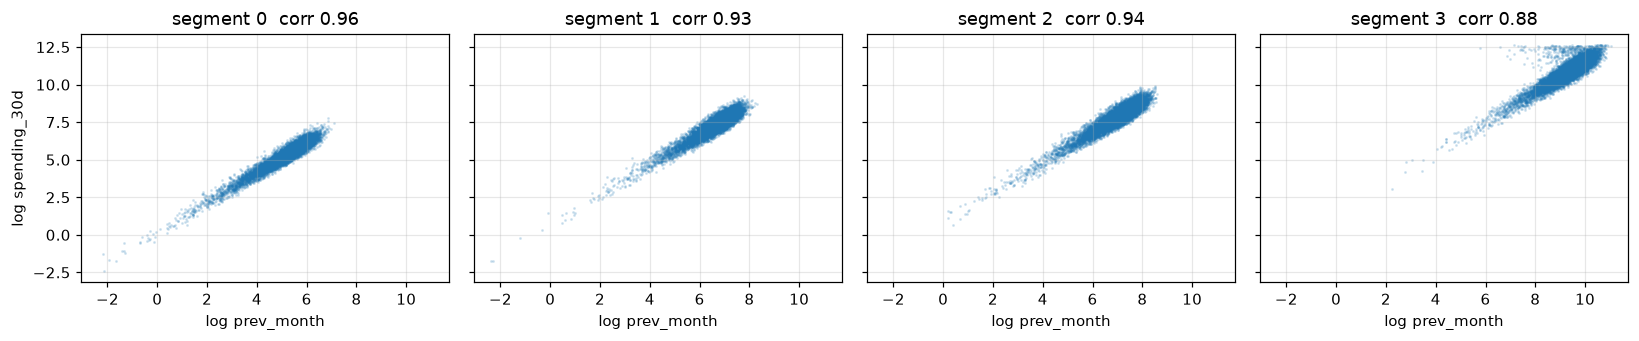

In [4]:
m = (raw.spending_30d > 0) & (raw.prev_month_spending > 0)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2), sharex=True, sharey=True)
for k, ax in enumerate(axs):
    s = raw[m & (raw.segment == k)]
    ax.scatter(np.log(s.prev_month_spending), np.log(s.spending_30d), s=1, alpha=.15)
    ax.set_title("segment %d  corr %.2f" % (k, np.corrcoef(np.log(s.prev_month_spending), np.log(s.spending_30d))[0, 1])); ax.set_xlabel("log prev_month")
axs[0].set_ylabel("log spending_30d"); plt.tight_layout(); plt.show()

### 2.3 Zero vs non-zero is hard to predict inside a segment

In [5]:
p10 = np.load("t3/preds/seedbag10/repo/t3/research/oof/bag_q10p10_p.npy")[:n]
print("P(y>0) classifier AUC overall: %.3f" % roc_auc_score(y > 0, p10))
print("AUC within segment:", {k: round(roc_auc_score(y[raw.segment.values == k] > 0, p10[raw.segment.values == k]), 3) for k in range(4) if (raw.segment.values == k).any()})

P(y>0) classifier AUC overall: 0.784
AUC within segment: {0: 0.605, 1: 0.628, 2: 0.601, 3: 0.567}


**Implications from EDA**
1. Fill purchase columns from the identities (NaN 5.8% → 0.4%).
2. Model the **ratio** y / prev_month instead of y, so the trees learn only the multiplier (Section 4).
3. Zero/non-zero is mostly decided by segment; inside a segment it is close to random. Any model will have irreducible error on zero-spending whales.
4. `segment` is missing for some rows. It is imputed with an XGBoost classifier trained on train rows with known segment (holdout accuracy 0.93). No target and no test rows are used.

## 3. Methodology
**Hurdle model.** Write the predictive distribution as a mixture: y = 0 with probability 1 − p, otherwise y ~ positive part G.
- **Classifier:** LightGBM gives p = P(y > 0).
- **Amount model:** CatBoost `MultiQuantile` loss learns 11 quantiles (α = 0.02 … 0.5) of G, trained on payers only.

**MAE-optimal prediction = median of the mixture.**
- If p ≤ 0.5, the median is 0.
- Otherwise the median is the quantile of G at level **q = 1 − 1/(2p)**: (1 − p) + p·q = 0.5 ⇒ q = 1 − 1/(2p).
- The rule has no tuned parameters, so the OOF score needs no nesting.

**Offset target.** The amount model learns r = log y − log prev_month (fallback log historical − 1.05). Predicted quantiles are mapped back with y = exp(Q_r + offset).

**Bagging.** 10 classifier seeds (p averaged) and 10 CatBoost seeds (quantiles geometric-mean averaged).

In [6]:
p_demo = np.array([.3, .5, .6, .8, .95, .99])
print(pd.DataFrame({"p = P(y>0)": p_demo, "quantile level used": np.where(p_demo > .5, 1 - 1 / (2 * p_demo), np.nan)}).round(3).to_string(index=False))

 p = P(y>0)  quantile level used
       0.30                  NaN
       0.50                  NaN
       0.60                0.167
       0.80                0.375
       0.95                0.474
       0.99                0.495


## 4. Key experiment: the offset target
A quick check on one fold: LightGBM median regression on payers, with and without the offset. The amount error is measured on payers.

In [7]:
import lightgbm as lgb
X, _ = extra_feats(D["X"], D["Xt"]); a, b = F[0]
pa, pb = a[y[a] > 0], b[y[b] > 0]
off = prev_offset(X)
res = {}
for name, tgt, add in [("log y", np.log(np.where(y > 0, y, 1)), 0 * off), ("log y - log prev (offset)", np.log(np.where(y > 0, y, 1)) - off, off)]:
    m_ = lgb.LGBMRegressor(objective="quantile", alpha=.5, n_estimators=600, learning_rate=.05, num_leaves=31, verbose=-1)
    m_.fit(X.iloc[pa], tgt[pa]); pr = np.exp(m_.predict(X.iloc[pb]) + add[pb])
    res[name] = {"MAE on payers": np.abs(y[pb] - pr).mean(), "error ratio Σ|e|/Σy": np.abs(y[pb] - pr).sum() / y[pb].sum()}
pd.DataFrame(res).T.round(4)

,MAE on payers,error ratio Σ|e|/Σy
log y,3752.4863,0.1855
log y - log prev (offset),3612.0973,0.1786


Full 5-fold results with XGBoost and LightGBM:

| model | OOF NMAE | gain |
|---|---|---|
| XGB multi-quantile on log y (reproduces the earlier v4) | 0.79162 | – |
| **+ offset log(prev_month)** | **0.79391** | **+0.0023** |
| LGB per-quantile on log y → with offset | 0.79002 → 0.79390 | **+0.0039** |
| offset from a fitted linear model instead of unit slope | 0.79223 | −0.0018 vs unit offset |

The unit-slope offset is better than a fitted one. The data was generated as prev × multiplier, so the trees only need to learn the multiplier.

## 5. Final model
Depth sweep with the offset target: CatBoost d4 ≈ d3 ≈ d6 > d8. XGB d5 ≥ d7 > d9. Shallow trees are enough for a multiplier.
Below, the hurdle rule is re-applied to the saved OOF arrays of the final model (Kaggle kernel `task3-seedbag10`).

In [8]:
O = "t3/preds/seedbag10/repo/t3/research/oof/"
ALPHAS = np.array([0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5])
rows = {}
for name in ["bag_q3p3", "bag_q10p3", "bag_q3p10", "bag_q10p10"]:
    Q, P = np.load(O + name + "_Q.npy"), np.load(O + name + "_p.npy")
    o = hurdle_median(P[:n], Q[:n], ALPHAS)
    s = np.array([nmae(y[b], o[b]) for _, b in F])
    rows[name] = {"OOF NMAE": nmae(y, o), "fold mean": s.mean(), "fold sd": s.std()}
r = pd.DataFrame(rows).T; r.index = ["3 CB × 3 clf seeds (previous final)", "10 CB × 3 clf", "3 CB × 10 clf", "10 CB × 10 clf (final)"]
r.round(5)

,OOF NMAE,fold mean,fold sd
3 CB × 3 clf seeds (previous final),0.79529,0.79534,0.00759
10 CB × 3 clf,0.79535,0.79540,0.00761
3 CB × 10 clf,0.79531,0.79535,0.00758
10 CB × 10 clf (final),0.79537,0.79542,0.00760


In [9]:
o = hurdle_median(np.load(O + "bag_q10p10_p.npy")[:n], np.load(O + "bag_q10p10_Q.npy")[:n], ALPHAS)
sg = raw.segment.fillna(-1).astype(int).values
err = pd.DataFrame({"rows": pd.Series(sg).value_counts().sort_index(),
                    "error ratio Σ|e|/Σy": pd.Series({k: np.abs(y[sg == k] - o[sg == k]).sum() / max(y[sg == k].sum(), 1) for k in np.unique(sg)}),
                    "share of total error %": pd.Series({k: 100 * np.abs(y[sg == k] - o[sg == k]).sum() / np.abs(y - o).sum() for k in np.unique(sg)})})
err.index.name = "segment (-1 = missing)"
print("final OOF NMAE %.5f | predicted zeros %.1f%% (true %.1f%%)" % (nmae(y, o), 100 * (o == 0).mean(), 100 * (y == 0).mean()))
err.round(3)

final OOF NMAE 0.79537 | predicted zeros 50.3% (true 48.1%)


,rows,error ratio Σ|e|/Σy,share of total error %
segment (-1 = missing),,,
-1,5935,0.247,5.957
0,39241,0.989,1.022
1,24483,0.726,5.972
2,19762,0.478,7.679
3,14579,0.234,79.369


## 6. What did not work (all OOF, same folds; noise level ≈ 0.0002)
| idea | result | why |
|---|---|---|
| Per-segment calibration (p-shift, scale), quantile-level shift, zeroing small predictions (nested) | ±0.00001 | the hurdle median is already MAE-optimal per row |
| Whale-specialist model | −0.0026 | less data; the general model already shares structure |
| Direct MAE on raw y (custom log-link) | 0.7795 | cannot produce exact zeros |
| Deeper trees / lower lr | ≤ 0 | the multiplier is a simple function |
| Stacking / LAD / greedy weights over 12 model families (nested) | −0.00003 to −0.00006 | weights unstable between folds; they fit noise |
| From-scratch MLP (quantile loss) | 0.7843, blend weight 0 | weaker than trees |
| Optuna tuning (31 trials) | lost on held-out folds | the gain on the tuning folds was noise |
| Remove noisy rows (top 1–10% residual, IsolationForest) | −0.0001 to −0.0003 | noise is spread over all rows, not concentrated in outliers |
| Fourier month features, CatBoost native categoricals, purchase-cadence features | −0.0001 to +0.0001 | noise |
| Upper quantiles (> 0.5) / scaling predictions ×0.95–×1.10 | ×1.0 best | q = 1 − 1/(2p) never exceeds 0.5 |

## 7. Ceiling
- **Error decomposition:** payer amount error 65%, zero-spenders predicted > 0 33%, payers predicted 0 2%.
- **Learning curve** (amount model on 25/50/75/100% of each fold): 0.79341 / 0.79445 / 0.79501 / 0.79512. Each doubling gives ~0.6× the previous gain, which extrapolates to **≈ 0.796–0.797** with unlimited data.
- **Classifier AUC** is flat at ~0.784–0.785 for any data size or model.
- **In-sample score** of the same model is only 0.8036. The target noise, not the model, limits the score.
- Conclusion: 0.7954 is within ~0.0015 of the data ceiling.

## 8. Submission

In [10]:
t = np.clip(np.load(O + "bag_q10p10_test.npy"), 0, None)
sub = pd.read_csv("submissions/FINAL/sub_v24b_noleak_T3seedbag10_T4blendEva02.csv")
print("test: zeros %.1f%%, mean %.0f | matches submitted file (2 d.p.): %s" % (100 * (t == 0).mean(), t.mean(), bool(np.allclose(sub.task3.values, np.round(t, 2), atol=0.006))))

test: zeros 50.4%, mean 10430 | matches submitted file (2 d.p.): True


**Summary of gains (OOF NMAE)**

| step | OOF |
|---|---|
| earlier v4 blend, honest nested weights | 0.79191 |
| + offset target log(y / prev_month) | 0.7939 |
| + CatBoost MultiQuantile, shallow (d4) | 0.79505 |
| + 3-seed bag | 0.79529 |
| + 10 × 10 seed bag (final) | **0.79537** |

**LB check:** the T3 = 0 probe dropped the public score by 0.0590 = 0.2 × 0.295. This matches a model score of 0.795 if all-zeros scores 0.5, which confirms both the metric formula and the CV.